# Hip annotation visualization

`rawdata/instances_default.json` is COCO instance segmentation. Each annotation has:

- **pixel masks** (primary) — uncompressed RLE in `segmentation`
- **bounding boxes** (derived) — `[x, y, width, height]` in `bbox`

This notebook loads DICOM images from `rawdata/` and shows **image | mask overlay | boxes** side by side.

**Kernel:** use the existing `medcv` conda env (no new packages required).

In [1]:
from pathlib import Path
import json

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

ROOT = Path('.').resolve()
if not (ROOT / 'rawdata' / 'instances_default.json').exists():
    ROOT = Path('/home/sochattopadhyay/workspace/hipsforJ')

RAW_DIR = ROOT / 'rawdata'
COCO_PATH = RAW_DIR / 'instances_default.json'
assert COCO_PATH.exists(), f'Missing {COCO_PATH}'
print('Project root:', ROOT)
print('Raw data:', RAW_DIR)

Data root: /home/sochattopadhyay/workspace/hipsforJ


## Helpers

DICOMs here are Explicit VR Little Endian (`1.2.840.10008.1.2.1`) with uncompressed `OW` pixel data. We read them with a small parser so we stay inside `medcv` (no `pydicom`).

In [3]:
CATEGORY_COLORS = {
    1: (1.0, 0.2, 0.2),   # Left Innominate Bone
    2: (0.2, 0.6, 1.0),   # Right Innominate Bone
    3: (0.2, 0.85, 0.3),  # Left Femur
    4: (1.0, 0.75, 0.1),  # Right Femur
}


def load_coco(path: Path):
    with open(path) as f:
        coco = json.load(f)
    cat_names = {c['id']: c['name'] for c in coco['categories']}
    images = {im['id']: im for im in coco['images']}
    anns_by_image = {}
    for ann in coco['annotations']:
        anns_by_image.setdefault(ann['image_id'], []).append(ann)
    return coco, cat_names, images, anns_by_image


def _find_us(raw: bytes, tag: bytes) -> int:
    i = 0
    while True:
        i = raw.find(tag, i)
        if i < 0:
            raise KeyError(f'DICOM tag not found: {tag!r}')
        if raw[i + 4:i + 6] == b'US':
            return int.from_bytes(raw[i + 8:i + 10], 'little')
        i += 1


def read_dicom_pixels(path: Path) -> np.ndarray:
    """Read 2D pixel array from uncompressed Explicit VR LE DICOM."""
    raw = Path(path).read_bytes()
    rows = _find_us(raw, b'\x28\x00\x10\x00')  # Rows
    cols = _find_us(raw, b'\x28\x00\x11\x00')  # Columns
    bits = _find_us(raw, b'\x28\x00\x00\x01')  # BitsAllocated
    pixrep = _find_us(raw, b'\x28\x00\x03\x01')  # PixelRepresentation
    expected = rows * cols * (bits // 8)

    tag = b'\xe0\x7f\x10\x00'  # PixelData
    start = 0
    data = None
    while True:
        i = raw.find(tag, start)
        if i < 0:
            break
        vr = raw[i + 4:i + 6]
        if vr in (b'OB', b'OW', b'OF', b'SQ', b'UT', b'UN'):
            length = int.from_bytes(raw[i + 8:i + 12], 'little')
            payload = raw[i + 12:i + 12 + length]
        else:
            length = int.from_bytes(raw[i + 6:i + 8], 'little')
            payload = raw[i + 8:i + 8 + length]
        if length == expected:
            data = payload
            break
        start = i + 1

    if data is None:
        raise RuntimeError(f'Uncompressed PixelData not found in {path}')

    dtype = '<u2' if (bits == 16 and pixrep == 0) else ('<i2' if bits == 16 else 'u1')
    return np.frombuffer(data, dtype=dtype).reshape(rows, cols)


def decode_rle(segmentation: dict) -> np.ndarray:
    """Decode COCO/CVAT uncompressed RLE -> binary mask (H, W)."""
    h, w = segmentation['size']
    flat = np.zeros(h * w, dtype=np.uint8)
    idx = 0
    val = 0
    for count in segmentation['counts']:
        flat[idx:idx + count] = val
        idx += count
        val ^= 1
    return flat.reshape((h, w), order='F')


def to_display(img: np.ndarray) -> np.ndarray:
    """Percentile window to float [0, 1] for display."""
    x = img.astype(np.float32)
    lo, hi = np.percentile(x, (1, 99))
    if hi <= lo:
        hi = lo + 1.0
    return np.clip((x - lo) / (hi - lo), 0, 1)


def overlay_masks(gray: np.ndarray, anns: list, alpha: float = 0.45) -> np.ndarray:
    rgb = np.stack([gray, gray, gray], axis=-1)
    out = rgb.copy()
    for ann in anns:
        mask = decode_rle(ann['segmentation']).astype(bool)
        color = np.array(CATEGORY_COLORS[ann['category_id']], dtype=np.float32)
        out[mask] = (1 - alpha) * out[mask] + alpha * color
    return out


coco, CAT_NAMES, IMAGES, ANNS_BY_IMAGE = load_coco(COCO_PATH)
print(f"{len(IMAGES)} images, {len(coco['annotations'])} annotations, categories:")
for cid, name in CAT_NAMES.items():
    print(f"  {cid}: {name}")

26 images, 88 annotations, categories:
  1: Left Innominate Bone
  2: Right Innominate Bone
  3: Left Femur
  4: Right Femur


## Side-by-side visualization

Showing image_ids: [7, 9, 1, 2]


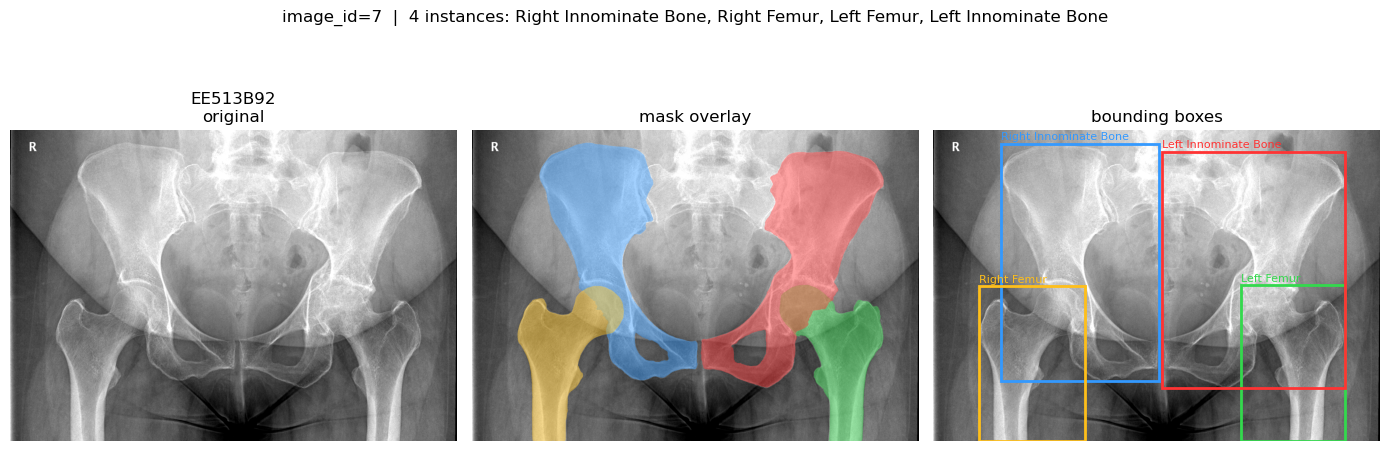

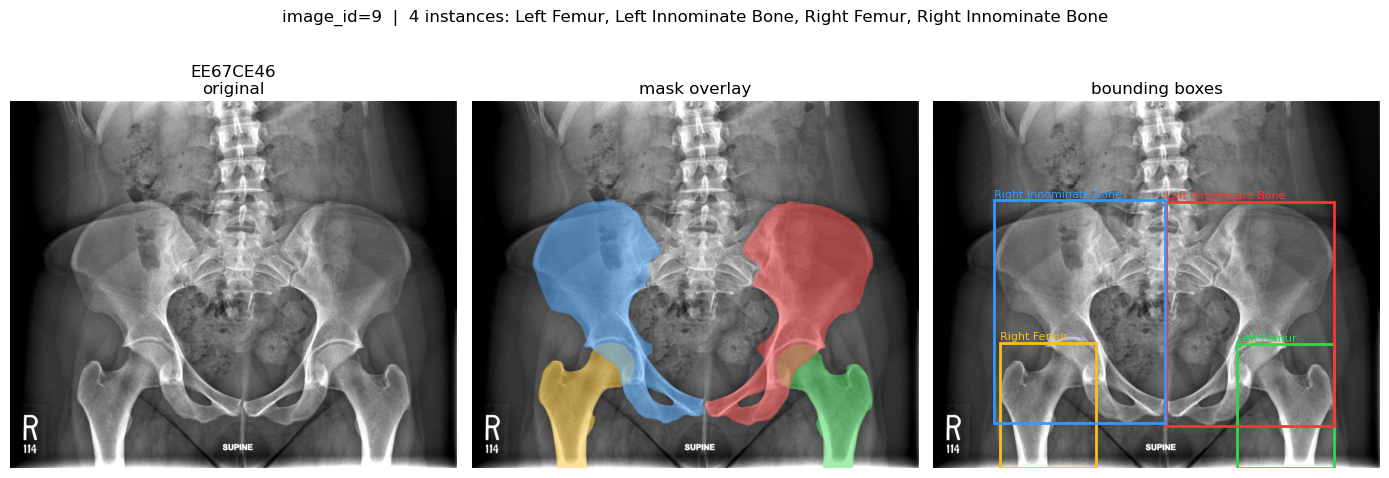

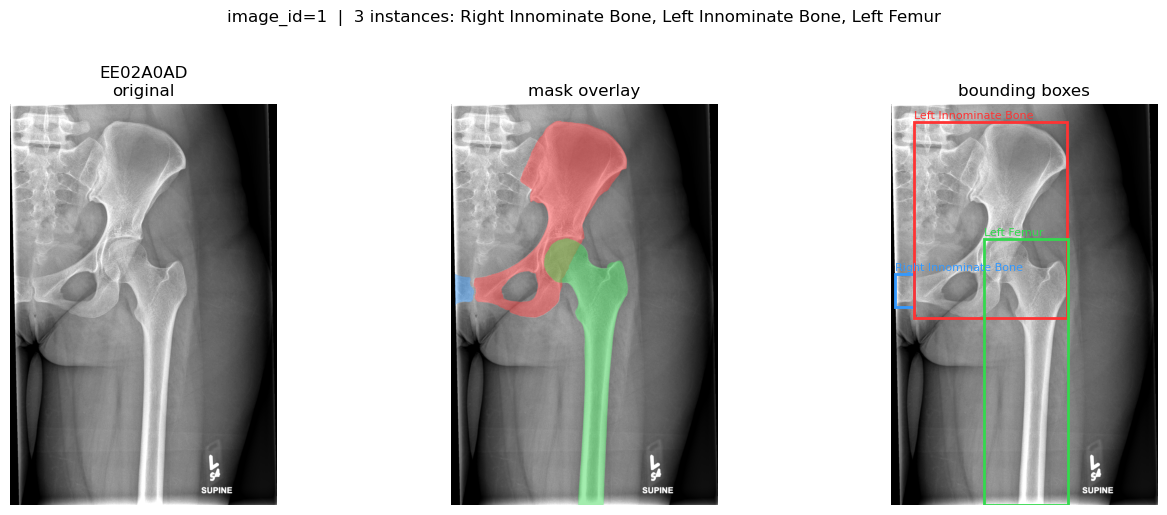

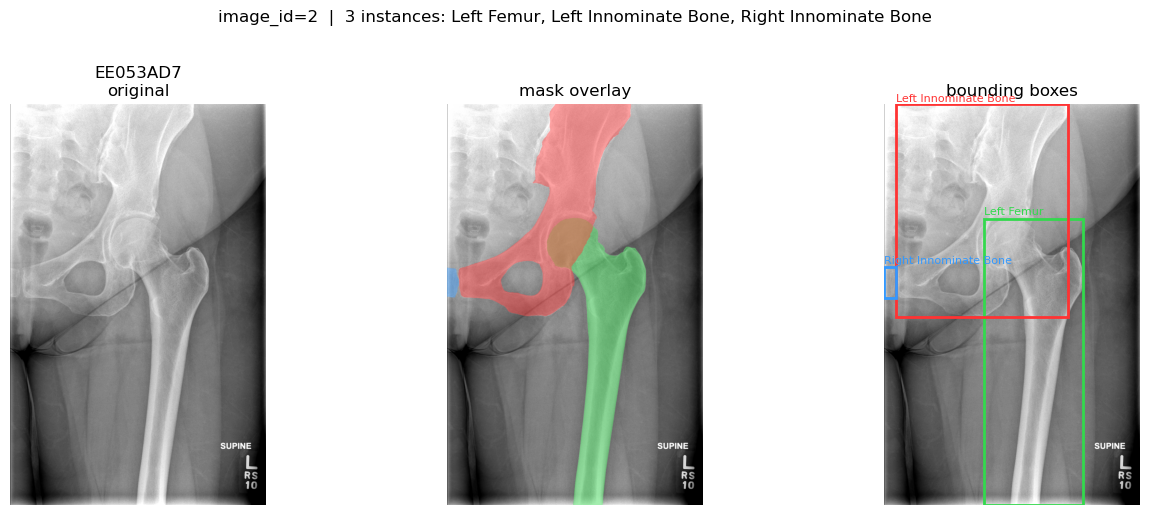

In [4]:
def show_sample(image_id: int, figsize=(14, 5)):
    meta = IMAGES[image_id]
    stem = Path(meta['file_name']).stem
    dcm_path = RAW_DIR / f'{stem}.dcm'
    anns = ANNS_BY_IMAGE.get(image_id, [])

    img = read_dicom_pixels(dcm_path)
    assert img.shape == (meta['height'], meta['width']), (
        f"Size mismatch for {stem}: DICOM {img.shape} vs JSON {(meta['height'], meta['width'])}"
    )
    gray = to_display(img)
    masked = overlay_masks(gray, anns)

    fig, axes = plt.subplots(1, 3, figsize=figsize)
    axes[0].imshow(gray, cmap='gray')
    axes[0].set_title(f'{stem}\noriginal')

    axes[1].imshow(masked)
    axes[1].set_title('mask overlay')

    axes[2].imshow(gray, cmap='gray')
    for ann in anns:
        x, y, w, h = ann['bbox']
        color = CATEGORY_COLORS[ann['category_id']]
        axes[2].add_patch(
            Rectangle((x, y), w, h, fill=False, edgecolor=color, linewidth=2)
        )
        axes[2].text(
            x, max(0, y - 8),
            CAT_NAMES[ann['category_id']],
            color=color, fontsize=8, va='bottom',
        )
    axes[2].set_title('bounding boxes')

    for ax in axes:
        ax.axis('off')

    labels = ', '.join(CAT_NAMES[a['category_id']] for a in anns) or '(none)'
    fig.suptitle(f'image_id={image_id}  |  {len(anns)} instances: {labels}', y=1.02)
    plt.tight_layout()
    plt.show()


# Prefer one fully labeled study, then a couple with missing classes
counts = {iid: len(anns) for iid, anns in ANNS_BY_IMAGE.items()}
full = [iid for iid, n in counts.items() if n == 4]
partial = [iid for iid, n in counts.items() if n < 4]
sample_ids = (full[:2] + partial[:2])[:4]
print('Showing image_ids:', sample_ids)

for iid in sample_ids:
    show_sample(iid)

## Optional: browse any study by stem

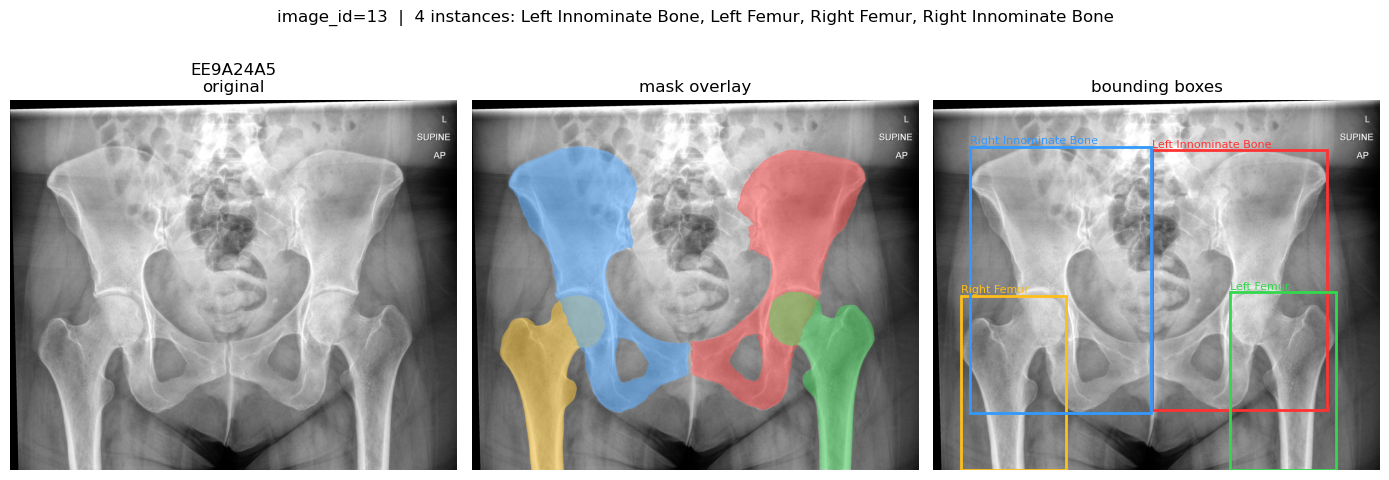

In [5]:
STEM = 'EE9A24A5'  # change as needed

match = next(im for im in IMAGES.values() if Path(im['file_name']).stem == STEM)
show_sample(match['id'])